# Project 2 — Credit Card Fraud Detection

**Name:** ATUHAIRE PAULINE 
**REG Number:** S25M19/016
**Access Number:** B35093
**Dataset:** 284,807 European card transactions over two days; 492 frauds (about 0.172%).

## 1. Problem formulation
The task is to prioritise transactions for human investigation, not to claim that a model can conclusively determine criminal intent. This is an extreme class-imbalance problem. Accuracy is misleading because a model predicting every transaction as legitimate would be over 99.8% accurate while detecting no fraud. Evaluation therefore emphasises average precision / PR-AUC, ROC-AUC, recall and precision among the highest-ranked transactions.

The dataset README states that V1–V28 are PCA components; `Time` is elapsed seconds and `Amount` is in euros; `Class=1` denotes fraud. Original feature meanings are unavailable because of confidentiality.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, confusion_matrix, classification_report,
                             precision_recall_curve)
RANDOM_STATE=42
DATA=Path("data/creditcard.csv")
if not DATA.exists():
    DATA=Path("../data/creditcard.csv")
df=pd.read_csv(DATA)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data understanding and preparation
Inspect dimensions, missingness, duplicates, class counts and amount distribution. Preserve the original PCA components. `Amount` is strongly skewed, so `log1p` is used; `Time` is retained and scaled. All preprocessing is fitted on the training split only to prevent test-set information leaking into model fitting. A stratified split preserves the rare fraud proportion in both sets.

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081


,count,share
Class,,
0,284315,0.998273
1,492,0.001727


           count          mean           std  min      25%      50%  \
Time    284807.0  94813.859575  47488.145955  0.0  54201.5  84692.0   
Amount  284807.0     88.349619    250.120109  0.0      5.6     22.0   

               75%        max  
Time    139320.500  172792.00  
Amount      77.165   25691.16  


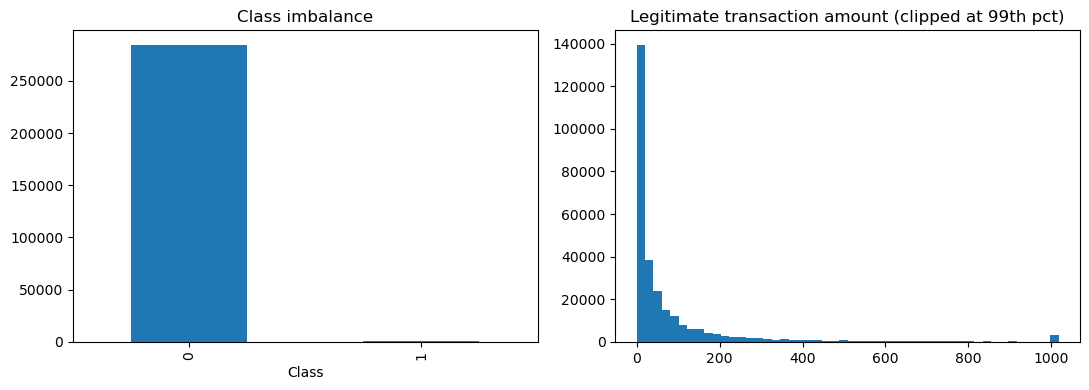

In [2]:
print("Shape:",df.shape)
print("Missing values:",int(df.isna().sum().sum()))
print("Duplicate rows:",int(df.duplicated().sum()))
counts=df.Class.value_counts().sort_index()
display(pd.DataFrame({"count":counts,"share":df.Class.value_counts(normalize=True).sort_index()}))
print(df[["Time","Amount"]].describe().T)
fig,axes=plt.subplots(1,2,figsize=(11,4))
df["Class"].value_counts().sort_index().plot(kind="bar",ax=axes[0]); axes[0].set_title("Class imbalance")
axes[1].hist(df.loc[df.Class==0,"Amount"].clip(upper=df.Amount.quantile(.99)),bins=50)
axes[1].set_title("Legitimate transaction amount (clipped at 99th pct)")
plt.tight_layout()

In [3]:
X_all=df.drop(columns="Class").copy()
y=df["Class"].astype(int)
X_all["Amount"]=np.log1p(X_all["Amount"].clip(lower=0))
# Keep identical feature rows in the same partition to reduce duplicate-pattern leakage.
groups=pd.util.hash_pandas_object(X_all,index=False).to_numpy()
splitter=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=RANDOM_STATE)
train_idx,test_idx=next(splitter.split(X_all,y,groups=groups))
X_train,X_test=X_all.iloc[train_idx].copy(),X_all.iloc[test_idx].copy()
y_train,y_test=y.iloc[train_idx].copy(),y.iloc[test_idx].copy()
print("Train:",X_train.shape,"fraud:",int(y_train.sum()))
print("Test:",X_test.shape,"fraud:",int(y_test.sum()))
print("Duplicate feature groups crossing partitions:",
      len(set(groups[train_idx]).intersection(set(groups[test_idx]))))
# Standardisation is fitted on training data only; PCA variables are already transformed,
# but scaling all columns makes Euclidean distances comparable for K-means.
scaler=StandardScaler()
X_train_s=scaler.fit_transform(X_train)
X_test_s=scaler.transform(X_test)

Train: (213625, 30) fraud: 342
Test: (71182, 30) fraud: 150
Duplicate feature groups crossing partitions: 0


## 3. Statistical outlier baseline
A robust univariate baseline computes the median and median absolute deviation (MAD) for each training feature. For each transaction, its anomaly score is the largest absolute robust z-score across features. This is deliberately simple and transparent. It cannot model interactions and an extreme value is not automatically fraud. It provides a ranking baseline rather than a definitive fraud threshold.

In [4]:
def robust_z_scores(train_frame, eval_frame):
    med=train_frame.median()
    mad=(train_frame-med).abs().median()
    # 1.4826 makes MAD comparable to standard deviation under a normal distribution.
    denom=1.4826*mad.replace(0,np.nan)
    rz=(eval_frame-med).abs().div(denom).replace([np.inf,-np.inf],np.nan).fillna(0)
    return rz
rz=robust_z_scores(X_train,X_test)
stat_score=rz.max(axis=1).to_numpy()

## 4. Ranking metrics
We calculate average precision (area under the precision-recall curve in the common sklearn definition), ROC-AUC, precision/recall at the top 0.5% and 1% of transactions, and precision/recall at a review capacity equal to the number of fraud cases in the test set. Top-k metrics reflect a finite investigation team. Threshold-dependent precision and recall must always be interpreted alongside the chosen review capacity.

In [5]:
def top_k_metrics(y_true, scores, fraction):
    y_true=np.asarray(y_true); scores=np.asarray(scores)
    k=max(1,int(np.ceil(len(scores)*fraction)))
    idx=np.argsort(scores)[::-1][:k]
    return {"k":k,"precision_at_k":precision_score(y_true[idx],np.ones(k),zero_division=0),
            "recall_at_k":float(y_true[idx].sum()/max(1,y_true.sum()))}
def evaluate(name,y_true,scores):
    out={"model":name,"average_precision":average_precision_score(y_true,scores),
         "roc_auc":roc_auc_score(y_true,scores)}
    for frac in [0.005,0.01]:
        m=top_k_metrics(y_true,scores,frac)
        out[f"precision_top_{frac:.1%}"]=m["precision_at_k"]
        out[f"recall_top_{frac:.1%}"]=m["recall_at_k"]
    m=top_k_metrics(y_true,scores,np.mean(y_true))
    out["precision_at_fraud_prevalence"]=m["precision_at_k"]
    out["recall_at_fraud_prevalence"]=m["recall_at_k"]
    return out
results=[evaluate("Robust statistical outlier",y_test,stat_score)]
pd.DataFrame(results).round(4)

,model,average_precision,roc_auc,precision_top_0.5%,recall_top_0.5%,precision_top_1.0%,recall_top_1.0%,precision_at_fraud_prevalence,recall_at_fraud_prevalence
0,Robust statistical outlier,0.0377,0.9298,0.0506,0.12,0.0492,0.2333,0.0467,0.0467


## 5. Cluster-based anomaly ranking — MiniBatch K-means
K-means is unsupervised: it does not use fraud labels to learn clusters. We fit MiniBatch K-means to the training feature vectors and use distance to the nearest learned centroid as an anomaly score. Transactions far from common centroids are ranked higher. MiniBatch K-means is chosen over full K-means for efficiency on approximately 285,000 records. The number of clusters is a modelling choice; a modest number captures broad regions without making the model prohibitively expensive. A high distance means unusual relative to this dataset, not necessarily fraudulent.

In [6]:
kmeans=MiniBatchKMeans(n_clusters=8,random_state=RANDOM_STATE,batch_size=4096,
                       n_init=5,max_iter=100)
kmeans.fit(X_train_s)  # no y_train used
cluster_score=kmeans.transform(X_test_s).min(axis=1)
results.append(evaluate("MiniBatch K-means distance",y_test,cluster_score))
pd.DataFrame(results).round(4)

,model,average_precision,roc_auc,precision_top_0.5%,recall_top_0.5%,precision_top_1.0%,recall_top_1.0%,precision_at_fraud_prevalence,recall_at_fraud_prevalence
0,Robust statistical outlier,0.0377,0.9298,0.0506,0.12,0.0492,0.2333,0.0467,0.0467
1,MiniBatch K-means distance,0.1866,0.9466,0.1770,0.42,0.1194,0.5667,0.2667,0.2667


## 6. Classification-based approach — class-weighted Random Forest
A supervised classifier can learn multivariate combinations associated with known fraud labels. A Random Forest is selected because it captures nonlinear interactions and provides probability scores without requiring linear decision boundaries. `class_weight='balanced_subsample'` increases the contribution of the rare fraud class within each tree's bootstrap sample. The model is trained only on the training partition. It is not trained on the test labels. The output probability of class 1 is used to rank transactions for review.

In [7]:
clf=RandomForestClassifier(n_estimators=100,max_depth=8,min_samples_leaf=3,
                           class_weight="balanced_subsample",n_jobs=-1,
                           random_state=RANDOM_STATE)
clf.fit(X_train_s,y_train)
class_score=clf.predict_proba(X_test_s)[:,1]
results.append(evaluate("Class-weighted Random Forest",y_test,class_score))
results_df=pd.DataFrame(results)
display(results_df.round(4))

,model,average_precision,roc_auc,precision_top_0.5%,recall_top_0.5%,precision_top_1.0%,recall_top_1.0%,precision_at_fraud_prevalence,recall_at_fraud_prevalence
0,Robust statistical outlier,0.0377,0.9298,0.0506,0.12,0.0492,0.2333,0.0467,0.0467
1,MiniBatch K-means distance,0.1866,0.9466,0.1770,0.42,0.1194,0.5667,0.2667,0.2667
2,Class-weighted Random Forest,0.8248,0.9785,0.3624,0.86,0.1812,0.8600,0.8200,0.8200


## 7. Precision-recall curves and investigation capacity
The PR curve is more informative than accuracy for this rare-event problem. The horizontal reference is the fraud prevalence in the test set; a useful ranking should improve substantially on this baseline. The top-k table makes the operational trade-off explicit: increasing review volume may capture more fraud but consumes more investigator time.

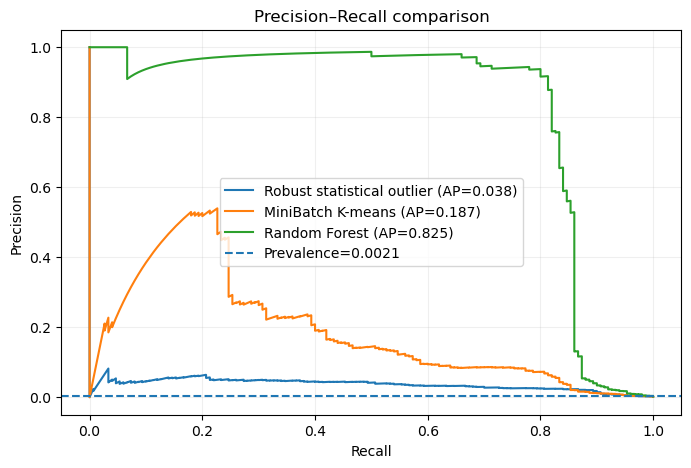

In [8]:
plt.figure(figsize=(8,5))
for name,score in [("Robust statistical outlier",stat_score),
                   ("MiniBatch K-means",cluster_score),
                   ("Random Forest",class_score)]:
    p,r,_=precision_recall_curve(y_test,score)
    plt.plot(r,p,label=f"{name} (AP={average_precision_score(y_test,score):.3f})")
plt.axhline(y_test.mean(),linestyle="--",label=f"Prevalence={y_test.mean():.4f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–Recall comparison")
plt.legend(); plt.grid(alpha=.2); plt.show()

In [9]:
# Top-ranked transactions for each review capacity
capacity_rows=[]
for name,score in [("Statistical",stat_score),("K-means",cluster_score),("Random Forest",class_score)]:
    for frac in [0.001,0.005,0.01,0.02]:
        m=top_k_metrics(y_test,score,frac)
        capacity_rows.append({"model":name,"review_share":frac,**m})
capacity=pd.DataFrame(capacity_rows)
display(capacity.round(4))

,model,review_share,k,precision_at_k,recall_at_k
0,Statistical,0.001,72,0.0694,0.0333
1,Statistical,0.005,356,0.0506,0.1200
2,Statistical,0.010,712,0.0492,0.2333
3,Statistical,0.020,1424,0.0435,0.4133
4,K-means,0.001,72,0.4722,0.2267
5,K-means,0.005,356,0.1770,0.4200
6,K-means,0.010,712,0.1194,0.5667
7,K-means,0.020,1424,0.0815,0.7733
8,Random Forest,0.001,72,0.9861,0.4733
9,Random Forest,0.005,356,0.3624,0.8600


## 8. Interpretation, limitations and responsible use
A transaction can be unusual without being fraudulent. It may reflect legitimate travel, a large one-off purchase, a new merchant, seasonal spending, a changed customer routine or a rare but valid transaction pattern. Conversely, fraud can be deliberately designed to resemble ordinary purchases. Outlier detection measures rarity; fraud detection estimates risk based on patterns and labelled examples. Human review and contextual evidence are therefore necessary before blocking a transaction or accusing a cardholder.

The PCA variables have no disclosed original meaning, limiting feature-level explanations. The data covers only two days in September 2013, so it may not represent current fraud patterns. Fraud labels may also reflect historical investigation and labelling processes. A random stratified split is useful for a reproducible benchmark but does not fully test future-time generalisation; a production study should use chronological validation and monitor concept drift. Model thresholds should be chosen using investigation capacity and the cost of false positives and false negatives. Protect cardholder privacy, restrict access to transaction data and provide an appeal/review process for declined transactions.

,random_forest_importance
V14,0.189979
V10,0.122710
V12,0.111549
V4,0.096821
V17,0.093756
V3,0.069757
V11,0.056974
V16,0.043783
V2,0.036096
V9,0.023792


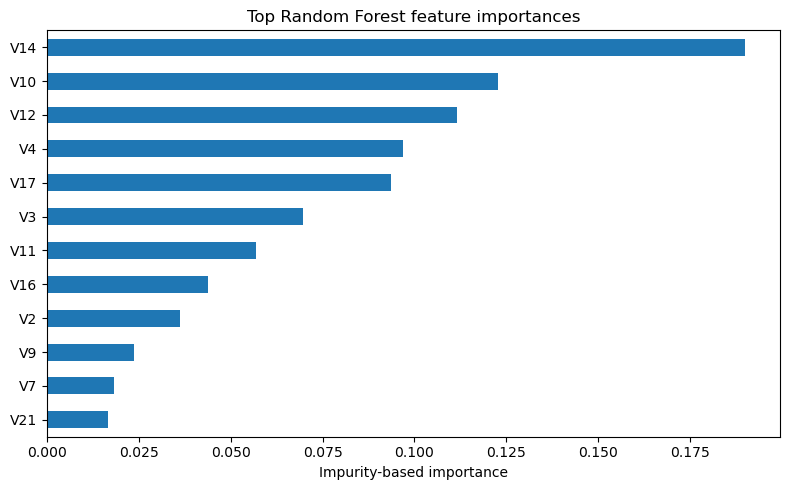

In [10]:
# Feature importance is descriptive, not causal; PCA components are not directly interpretable.
importance=pd.Series(clf.feature_importances_,index=X_all.columns).sort_values(ascending=False).head(12)
display(importance.to_frame("random_forest_importance"))
importance.sort_values().plot(kind="barh",figsize=(8,5),title="Top Random Forest feature importances")
plt.xlabel("Impurity-based importance"); plt.tight_layout(); plt.show()